In [1]:
# Fan In Fan Out
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class BlogState(TypedDict):
    topic: str
    intro: str
    examples: str
    code: str
    final_blog: str
    valid: bool


In [2]:
def planner(state: BlogState):
    return state

def write_intro(state: BlogState):
    return {
        "intro" :  f"Intro about {state['topic']}"
    }

def write_examples(state):
    return {
        "examples" :  "Real-world Examples"
    }

def write_code(state: BlogState):
    return {
        "code" : "LangGaph Code Snippet"
    }

def merge_content(state: BlogState):
    final = (
        state['intro'] + "\n" +
        state['examples'] + "\n" +
        state['code'] + "\n"
    )

    return {
        "final_blog" : final
    }

    

In [3]:
# Subgraph/component
def check_length(state: BlogState):
    topic = state['topic']
    if len(topic) < 5:
        state['valid'] = False
    else:
        state['valid'] = True
    print(f'check_length valid: {state}')
    return state

validation_graph_builder = StateGraph(BlogState)

validation_graph_builder.add_node("check_length", check_length)
validation_graph_builder.add_edge(START, "check_length")
validation_graph_builder.add_edge("check_length", END)

validation_graph = validation_graph_builder.compile()
validation_graph

result = validation_graph.invoke({
    "topic" : "AI"
})
print(result)


check_length valid: {'topic': 'AI', 'valid': False}
{'topic': 'AI', 'valid': False}


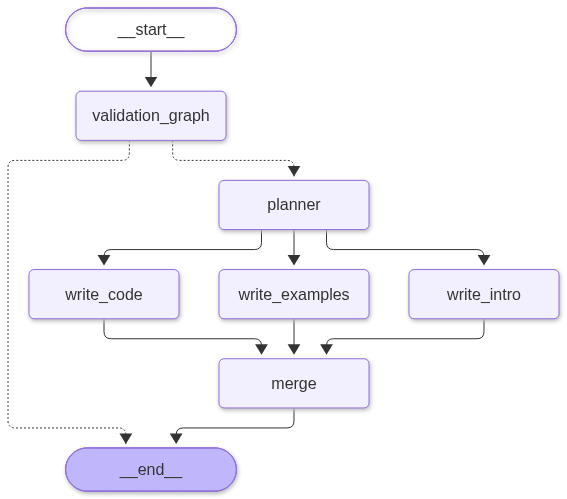

In [4]:
graph = StateGraph(BlogState)

graph.add_node("planner", planner)
graph.add_node("write_intro", write_intro)
graph.add_node("write_examples", write_examples)
graph.add_node("write_code", write_code)
graph.add_node("merge", merge_content)

# Every graph is a valid node in LangGraph
graph.add_node("validation_graph", validation_graph)

graph.add_edge(START, "validation_graph")


graph.add_conditional_edges(
    "validation_graph",
    lambda _state: "planner" if _state['valid'] else END,
    {
        "planner": "planner",
        END: END
    }
)

graph.add_edge("planner", "write_intro")
graph.add_edge("planner", "write_examples")
graph.add_edge("planner", "write_code")

graph.add_edge("write_intro", "merge")
graph.add_edge("write_examples", "merge")
graph.add_edge("write_code", "merge")

graph.add_edge("merge", END)

app = graph.compile()
app


In [6]:
result = app.invoke({
    "topic" : "Generative AI"
})

print(result)


check_length valid: {'topic': 'Generative AI', 'valid': True}
{'topic': 'Generative AI', 'intro': 'Intro about Generative AI', 'examples': 'Real-world Examples', 'code': 'LangGaph Code Snippet', 'final_blog': 'Intro about Generative AI\nReal-world Examples\nLangGaph Code Snippet\n', 'valid': True}
